k=2 factors | Log-likelihood: -12.34
k=3 factors | Log-likelihood: -11.84
k=4 factors | Log-likelihood: -11.84


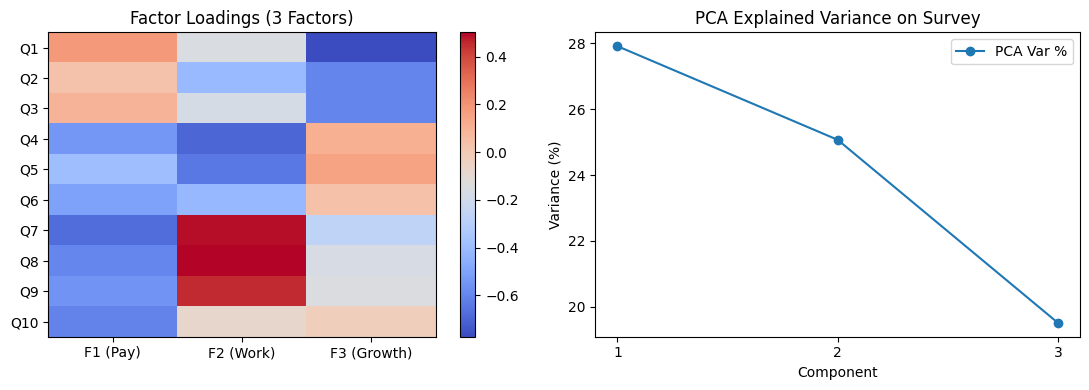

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis, PCA

rng = np.random.default_rng(42)
n = 300
f_pay = rng.normal(size=n)
f_work = rng.normal(size=n)
f_growth = rng.normal(size=n)

data = np.column_stack([
    3.5 + 0.9*f_pay + rng.normal(0, 0.5, n),
    3.5 + 0.8*f_pay + 0.2*f_work + rng.normal(0, 0.5, n),
    3.5 + 0.7*f_pay + rng.normal(0, 0.6, n),
    3.2 + 0.9*f_work + rng.normal(0, 0.5, n),
    3.2 + 0.8*f_work + rng.normal(0, 0.5, n),
    3.2 + 0.7*f_work + 0.2*f_growth + rng.normal(0, 0.6, n),
    3.4 + 0.9*f_growth + rng.normal(0, 0.5, n),
    3.4 + 0.8*f_growth + rng.normal(0, 0.5, n),
    3.4 + 0.7*f_growth + rng.normal(0, 0.6, n),
    3.3 + 0.5*f_work + 0.5*f_growth + rng.normal(0, 0.6, n),
])
df = pd.DataFrame(np.clip(np.round(data), 1, 5), columns=[f"Q{i+1}" for i in range(10)])

for k in [2, 3, 4]:
    fa = FactorAnalysis(n_components=k, random_state=42).fit(df)
    print(f"k={k} factors | Log-likelihood: {fa.score(df):.2f}")

fa3 = FactorAnalysis(n_components=3, random_state=42).fit(df)
pca3 = PCA(n_components=3).fit(df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(fa3.components_.T, cmap="coolwarm", aspect="auto")
axes[0].set_yticks(range(10)); axes[0].set_yticklabels(df.columns)
axes[0].set_xticks([0, 1, 2]); axes[0].set_xticklabels(["F1 (Pay)", "F2 (Work)", "F3 (Growth)"])
axes[0].set_title("Factor Loadings (3 Factors)")
plt.colorbar(im, ax=axes[0])

axes[1].plot(range(1, 4), pca3.explained_variance_ratio_ * 100, marker="o", label="PCA Var %")
axes[1].set_xticks([1, 2, 3]); axes[1].set_xlabel("Component"); axes[1].set_ylabel("Variance (%)")
axes[1].set_title("PCA Explained Variance on Survey"); axes[1].legend()
plt.tight_layout(); plt.show()